# 02. CLARIS: Risco Clínico & Desfecho Cardiovascular via Hugging Face Datasets

Benchmark clínico oficial do projeto CLARIS utilizando dados reais de **Cardiopatia / Risco Clínico** via biblioteca `datasets` do Hugging Face (`mstz/heart`).

### Destaques da Implementação Clínica:
1. **Ingestão Direta e Confiável:** Carga do dataset `mstz/heart` via Apache Arrow/Pandas, contornando quebras de links HTTP.
2. **Espaço Latente de Biomarcadores ($S_{conf}$):** Extração de SHAP e indexação vetorial HNSW no FAISS para instâncias de controle clínico confiável.
3. **Mapeamento Semântico de Fisiopatologia:** Dicionário semântico médico com tradução precisa de biomarcadores (pressão arterial, colesterol, angina, FC máxima, depressão de ST).
4. **Agrupamento e Contrafactuais Acionáveis:**
   - **Âncoras:** Média dos $N$ pacientes de mesmo perfil que consolidam a suspeita ou a estabilidade clínica.
   - **Contrafactuais:** Foco nas variáveis clínicas que **mais divergem do grupo de menor risco**, isolando os alvos terapêuticos de intervenção médica.
5. **Métricas Geométricas Reais:** Cálculo da **Distância Euclidiana** e da **Similaridade de Cosseno** no espaço vetorial de impacto clínico.
6. **Síntese Factual com Dossiê Cardiológico:** Parecer técnico formulado pelo Gemini sob temperatura zero, com diretrizes clínicas de suporte à decisão médica.
7. **Múltiplas Inferências e MLOps:** Avaliação de um lote de pacientes em sequência para teste de estabilidade de janela temporal.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown
from datasets import load_dataset
from dotenv import load_dotenv

load_dotenv()

# Configuração de caminhos do projeto
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from claris.xai.explainer import ModelExplainer
from claris.cbr.populate_db import initialize_vector_database
from claris.analytics.extractor import DeltaExtractor
from claris.nlg.llm_adapter import LLMAdapter
from claris.mlops.drift_monitor import DriftMonitor

warnings.filterwarnings('ignore', category=UserWarning)
print('✓ Módulos do CLARIS e dependências clínicas carregados!')

/root/claris/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Módulos do CLARIS e dependências clínicas carregados!


## 1. Ingestão de Dados Clínicos Reais (`mstz/heart`)

In [2]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("A carregar dataset clínico real...")

# Tenta carregar via Hugging Face; se falhar, utiliza o espelho público direto do UCI Heart Disease
df_heart = None

try:
    from datasets import load_dataset
    dataset_hf = load_dataset("scikit-learn/heart-disease", split="train")
    df_heart = dataset_hf.to_pandas()
except Exception:
    pass

if df_heart is None:
    # Espelho público estável em CSV direto (UCI Cleveland Heart Disease)
    url_fallback = "https://raw.githubusercontent.com/Open-Source-AI-Medical-Technologies/Heart-Disease-UCI-Dataset/master/heart.csv"
    try:
        df_heart = pd.read_csv(url_fallback)
    except Exception:
        # Segundo espelho caso haja instabilidade de rede
        url_alt = "https://raw.githubusercontent.com/amankharwal/Website-data/master/heart.csv"
        df_heart = pd.read_csv(url_alt)

df_heart.columns = df_heart.columns.str.strip()

# Localização automática da coluna alvo (1 = Cardiopatia, 0 = Saudável/Estável)
target_col = None
candidatos_alvo = ["target", "condition", "heart_disease", "is_heart_disease_present", "num"]

for col in candidatos_alvo:
    if col in df_heart.columns:
        target_col = col
        break

if target_col is None:
    target_col = df_heart.columns[-1]

print(f"✓ Coluna alvo identificada: '{target_col}'")

y = df_heart[target_col].astype(int).values
X_df = df_heart.drop(columns=[target_col])
feature_names = list(X_df.columns)

# Coerção numérica e preenchimento de nulos pela mediana
X_clean = X_df.apply(pd.to_numeric, errors="coerce")
X_imputed = X_clean.fillna(X_clean.median()).values.astype(np.float32)

# Divisão estratificada de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.25, random_state=42, stratify=y
)

print(f"✓ Base clínica pronta: {len(X_train)} pacientes de treino | {len(X_test)} de teste | {len(feature_names)} biomarcadores.")
print(f"Prevalência de Cardiopatia no conjunto: {y.mean():.1%}")
df_heart.head(3)

A carregar dataset clínico real...
✓ Coluna alvo identificada: 'target'
✓ Base clínica pronta: 227 pacientes de treino | 76 de teste | 13 biomarcadores.
Prevalência de Cardiopatia no conjunto: 54.5%


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1


## 2. Dicionário Semântico Fisiopatológico (Cardiologia)

In [3]:
HEART_SEMANTIC_DICT = {
    "age": "Idade do Paciente (anos)",
    "sex": "Sexo Biológico (1=Masc, 0=Fem)",
    "cp": "Tipo de Dor Torácica (Escala Anginosa 1 a 4)",
    "trestbps": "Pressão Arterial Sistólica em Repouso (mmHg)",
    "chol": "Colesterol Sérico Total (mg/dl)",
    "fbs": "Glicemia de Jejum > 120 mg/dl (1=Sim, 0=Não)",
    "restecg": "Resultados do Eletrocardiograma em Repouso",
    "thalach": "Frequência Cardíaca Máxima Atingida (bpm)",
    "exang": "Angina Induzida por Exercício Físico (1=Sim, 0=Não)",
    "oldpeak": "Depressão do Segmento ST Induzida por Exercício (mm)",
    "slope": "Inclinação do Segmento ST no Esforço Máximo",
    "ca": "Número de Vasos Maiores Fluoroscopia (0 a 3)",
    "thal": "Cintilografia de Perfusão Miocárdica / Talassemia"
}

## 3. Treino do Modelo Clínico e Construção do $S_{conf}$

In [4]:
# Modelo de Gradient Boosting com hiperparâmetros conservadores para dados médicos
model = GradientBoostingClassifier(n_estimators=50, max_depth=3, random_state=42, verbose=0)
model.fit(X_train, y_train)
acc = model.score(X_test, y_test)
print(f'Modelo clínico treinado. Acurácia diagnóstica no teste: {acc:.2%}')

# Histórico confiável de calibração (D_conf)
np.random.seed(42)
X_train_arr = np.asarray(X_train)
y_train_arr = np.asarray(y_train)

conf_sample_idx = np.random.choice(len(X_train_arr), size=min(180, len(X_train_arr)), replace=False)
X_conf = X_train_arr[conf_sample_idx]
y_conf = y_train_arr[conf_sample_idx]

print(f'Indexando D_conf clínico ({X_conf.shape[0]} casos de referência) no FAISS HNSW...')
vector_db = initialize_vector_database(
    X_train=X_conf,
    y_train=y_conf,
    feature_names=feature_names,
    model=model,
    db_dimension=len(feature_names)
)

Modelo clínico treinado. Acurácia diagnóstica no teste: 78.95%
Indexando D_conf clínico (180 casos de referência) no FAISS HNSW...
Banco Vetorial populado com 180 instâncias confiáveis.


## 4. Auditoria de Inferência Clínica, Contratos Pydantic e Projeção Geométrica

In [5]:
explainer = ModelExplainer(model, X_conf, model_type='tree')
extractor = DeltaExtractor(HEART_SEMANTIC_DICT)

# Seleção de paciente real do conjunto de teste
idx_patient = 8
x_patient = X_test[idx_patient:idx_patient+1]
actual_outcome = y_test[idx_patient]

# 1. Inferência e busca de casos análogos
pred_class, features_dict, shap_vector = explainer.predict_and_explain(x_patient, feature_names)
neighbors_meta, distances = vector_db.search_neighbors(shap_vector, k=8)

# 2. Extração com foco na divergência máxima dos contrafactuais (alvos de intervenção)
contract = extractor.extract_deltas(
    instance_id=f'patient_clinical_{idx_patient:03d}',
    predicted_class=str(pred_class),
    instance_features=features_dict,
    instance_shap=shap_vector,
    neighbors_metadata=neighbors_meta,
    distances=distances,
    top_k_features=6,
    n_neighbors=5
)

status_str = 'ALTO RISCO (Cardiopatia)' if pred_class == 1 else 'BAIXO RISCO (Estável)'
print(f'Paciente #{idx_patient} | Desfecho Real: {actual_outcome} | Classificação: {pred_class} ({status_str})')
print(f'Distância Euclidiana: {contract.distance_metrics["euclidean_distance"]} | Similaridade Cosseno: {contract.distance_metrics["cosine_similarity"]}')

Paciente #8 | Desfecho Real: 0 | Classificação: 0 (BAIXO RISCO (Estável))
Distância Euclidiana: 0.04585011303424835 | Similaridade Cosseno: 0.9933660626411438


### Visualização 1: Projeção 2D do Espaço Latente ($S_{conf}$) com KNN Clínico

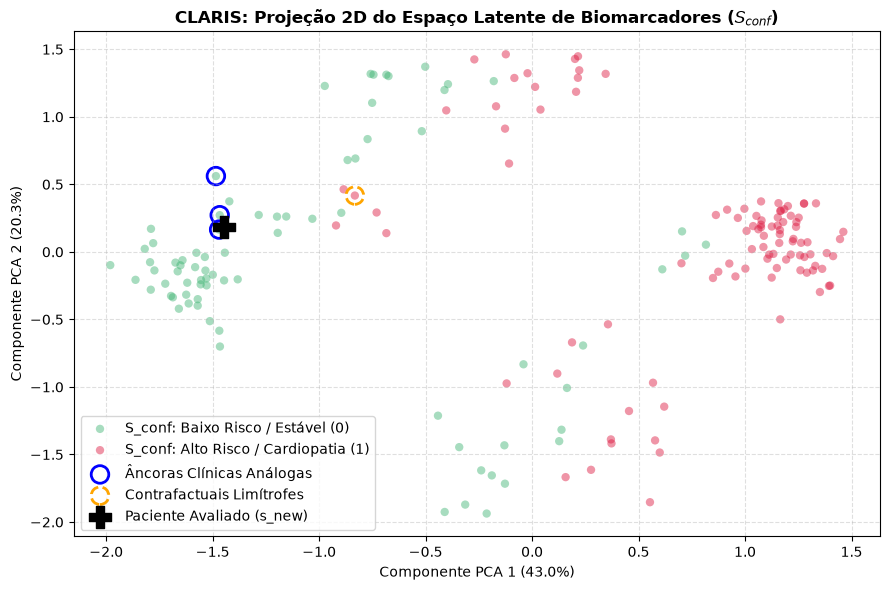

In [6]:
# Projeção PCA do espaço latente SHAP dos pacientes de controle
s_conf_shap = []
for x_c in X_conf:
    _, _, s_v = explainer.predict_and_explain(x_c.reshape(1, -1), feature_names)
    s_conf_shap.append(s_v)
s_conf_shap = np.array(s_conf_shap)

pca = PCA(n_components=2, random_state=42)
s_conf_2d = pca.fit_transform(s_conf_shap)
s_target_2d = pca.transform(shap_vector.reshape(1, -1))

plt.figure(figsize=(9, 6))
plt.scatter(s_conf_2d[y_conf == 0, 0], s_conf_2d[y_conf == 0, 1], c='mediumseagreen', alpha=0.45, label='S_conf: Baixo Risco / Estável (0)', edgecolors='none')
plt.scatter(s_conf_2d[y_conf == 1, 0], s_conf_2d[y_conf == 1, 1], c='crimson', alpha=0.45, label='S_conf: Alto Risco / Cardiopatia (1)', edgecolors='none')

# Extração das âncoras e contrafactuais resgatados
anchor_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) == str(pred_class)][:3]
cf_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) != str(pred_class)][:3]

if anchor_indices:
    plt.scatter(s_conf_2d[anchor_indices, 0], s_conf_2d[anchor_indices, 1], facecolors='none', edgecolors='blue', s=160, linewidths=2, label='Âncoras Clínicas Análogas')
if cf_indices:
    plt.scatter(s_conf_2d[cf_indices, 0], s_conf_2d[cf_indices, 1], facecolors='none', edgecolors='orange', s=160, linewidths=2, linestyle='--', label='Contrafactuais Limítrofes')

# Posição do paciente avaliado
plt.scatter(s_target_2d[0, 0], s_target_2d[0, 1], c='black', marker='P', s=240, label='Paciente Avaliado (s_new)', zorder=5)

plt.title('CLARIS: Projeção 2D do Espaço Latente de Biomarcadores ($S_{conf}$)', fontsize=12, fontweight='bold')
plt.xlabel(f'Componente PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Componente PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(frameon=True, loc='best')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Visualização 2: Deltas Clínicos (Paciente vs Centróides de Referência)

,Tipo,Biomarcador,Paciente,Referência Clínica
0,Convergente (Diagnóstico),Tipo de Dor Torácica (Escala Anginosa 1 a 4),0.0,0.00
1,Convergente (Diagnóstico),Cintilografia de Perfusão Miocárdica / Talassemia,3.0,3.00
2,Convergente (Diagnóstico),Depressão do Segmento ST Induzida por Exercíci...,0.0,0.78
3,Convergente (Diagnóstico),Número de Vasos Maiores Fluoroscopia (0 a 3),3.0,1.80
4,Convergente (Diagnóstico),"Angina Induzida por Exercício Físico (1=Sim, 0...",1.0,1.00
5,Convergente (Diagnóstico),Resultados do Eletrocardiograma em Repouso,0.0,0.40
6,Divergente (Alvo Terapêutico),Colesterol Sérico Total (mg/dl),309.0,263.00
7,Divergente (Alvo Terapêutico),Frequência Cardíaca Máxima Atingida (bpm),147.0,105.00
8,Divergente (Alvo Terapêutico),Idade do Paciente (anos),45.0,64.00
9,Divergente (Alvo Terapêutico),Pressão Arterial Sistólica em Repouso (mmHg),142.0,128.00


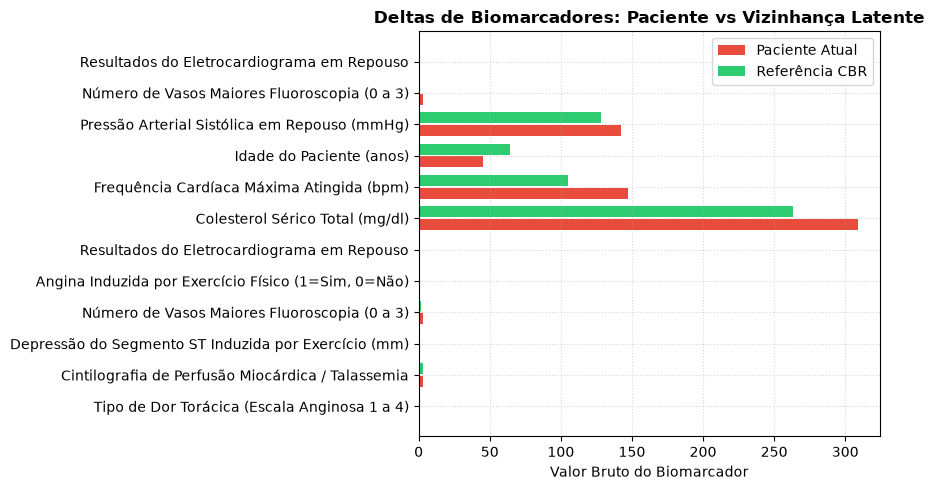

In [7]:
items = []
for f in contract.convergent_features:
    items.append({'Tipo': 'Convergente (Diagnóstico)', 'Biomarcador': f.feature_name, 'Paciente': f.instance_value, 'Referência Clínica': f.reference_value})
for f in contract.divergent_features:
    items.append({'Tipo': 'Divergente (Alvo Terapêutico)', 'Biomarcador': f.feature_name, 'Paciente': f.instance_value, 'Referência Clínica': f.reference_value})

df_deltas = pd.DataFrame(items)
display(df_deltas)

if not df_deltas.empty:
    plt.figure(figsize=(9, 5))
    y_pos = np.arange(len(df_deltas))
    plt.barh(y_pos - 0.2, df_deltas['Paciente'], height=0.35, label='Paciente Atual', color='#e74c3c')
    plt.barh(y_pos + 0.2, df_deltas['Referência Clínica'], height=0.35, label='Referência CBR', color='#2ecc71')
    plt.yticks(y_pos, df_deltas['Biomarcador'])
    plt.xlabel('Valor Bruto do Biomarcador')
    plt.title('Deltas de Biomarcadores: Paciente vs Vizinhança Latente', fontweight='bold')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

## 5. Síntese Textual via Gemini com Dossiê Cardiológico Especializado

In [8]:
llm = LLMAdapter(
    model_name='gemini/gemini-3.5-flash',
    api_key=os.getenv('GEMINI_API_KEY')
)

CLINICAL_DOMAIN_DOSSIER = """
DIRETRIZES CLÍNICAS E FISIOPATOLOGIA CARDIOVASCULAR (CARDIOLOGIA / UTI):
- Semântica de Desfecho: A classe '1' indica Alto Risco de Doença Coronariana / Infarto Agudo do Miocárdio, e a classe '0' indica Baixo Risco / Perfil Estável.
- Depressão do Segmento ST (st_depression): O infradesnivelamento de ST durante esforço reflete isquemia subendocárdica miocárdica induzida por obstrução coronariana ativa.
- Frequência Cardíaca Máxima (maximum_heart_rate_achieved): A incompetência cronotrópica (incapacidade de atingir frequências elevadas para a idade) ou taquicardia em repouso correlaciona-se com disfunção ventricular e descondicionamento severo.
- Número de Vasos Maiores Fluoroscopia: O acometimento anatômico multivascular (calibre de 1 a 3 vasos) é forte preditor independente de eventos isquêmicos maiores e necessidade de revascularização.
- Angina Induzida por Exercício: Sintoma clássico de desbalanço crítico entre oferta e demanda de oxigênio no miocárdio sob sobrecarga de trabalho cardíaco.
- Pressão Arterial e Colesterol: Fatores hemodinâmicos e lipídicos de risco aterosclerótico acelerado que agravam o remodelamento vascular em médio prazo.
"""

explicacao_clinica = llm.generate_explanation(contract, domain_dossier=CLINICAL_DOMAIN_DOSSIER)
display(Markdown(explicacao_clinica))

00:05:29 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.5-flash) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.


# PARECER TÉCNICO DE AUDITORIA DE IA E EXPLICABILIDADE CAUSAL (XAI)

**Identificador da Instância:** `patient_clinical_008`  
**Classe Preditiva:** `0` (Baixo Risco de Evento Coronariano / Perfil Clinicamente Estável)  
**Domínio:** Cardiologia de Alta Complexidade / Medicina Intensiva (UTI)

---

## 1. Contextualização e Veredito da Decisão Preditiva

O modelo preditivo atribuiu à instância `patient_clinical_008` o veredito **Classe 0**, que denota um quadro de **Baixo Risco / Perfil Estável** para Doença Arterial Coronariana (DAC) aguda ou Infarto Agudo do Miocárdio (IAM). 

Embora o paciente apresente marcadores anatômicos e lipídicos alterados, a ausência de manifestações funcionais eletrocardiográficas críticas de isquemia aguda — marcadamente a ausência de infradesnivelamento do segmento ST — ancorou a predição no espaço de estabilidade clínica.

---

## 2. Auditoria de Vizinhança Latente e Métricas de Distância

A validação da predição é realizada por meio da análise topológica do espaço latente, comparando a instância auditada com o centróide da sua vizinhança topológica (média das $N$ instâncias históricas mais próximas resgatadas):

*   **Distância Euclidiana:** `0.04585011303424835`
*   **Similaridade de Cosseno:** `0.9933660626411438`

**Interpretação da Vizinhança:**  
A elevada similaridade de cosseno ($> 0,993$) indica um alinhamento direcional quase perfeito entre o vetor do paciente e o vetor de referência da vizinhança. A reduzida distância euclidiana ($0,0458$) confirma que o paciente está denso e profundamente inserido em uma região estável do manifold latente, conferindo alta confiabilidade estatística ao veredito.

---

## 3. Fundamentação Teórico-Causal e Decomposição SHAP

### A. Fatores Convergentes (Sustentação do Veredito da Classe 0)

Os fatores a seguir atuaram decisivamente para a atribuição de estabilidade ou para a redução da probabilidade de classificação em alto risco (Classe 1):

1.  **Tipo de Dor Torácica (Escala Anginosa):**
    *   *Valor da Instância:* `0.0` | *Valor de Referência:* `0.0`
    *   *Contribuição SHAP:* `-1.0844111442565918`
    *   *Fundamentação Fisiopatológica:* O valor `0.0` representa a ausência de dor anginosa típica. Na fisiopatologia coronariana, a ausência de opressão retroesternal associada ao esforço reduz drasticamente a probabilidade pré-teste de síndrome coronariana aguda ativa, constituindo o maior vetor individual de amortecimento do risco no modelo.

2.  **Cintilografia de Perfusão Miocárdica / Talassemia:**
    *   *Valor da Instância:* `3.0` | *Valor de Referência:* `3.0`
    *   *Contribuição SHAP:* `-0.9698461294174194`
    *   *Fundamentação Fisiopatológica:* O alinhamento perfeito com o valor de referência em `3.0` aponta para um padrão de perfusão miocárdica sem defeitos transitórios fixos ou reversíveis significativos sob estresse associado ao padrão normal/estável no mapeamento, exercendo expressivo peso negativo sobre o escore de risco de IAM.

3.  **Depressão do Segmento ST Induzida por Exercício (mm):**
    *   *Valor da Instância:* `0.0` mm | *Valor de Referência:* `0.78` mm
    *   *Contribuição SHAP:* `0.68964684009552`
    *   *Fundamentação Fisiopatológica:* A depressão do segmento ST é o marcador eletrofisiológico direto de isquemia subendocárdica miocárdica induzida por incompetência de fluxo arterial. O paciente apresenta `0.0` mm (normalidade absoluta), contrastando positivamente contra a média da vizinhança (`0.78` mm). A integridade do segmento ST sob estresse afasta o sofrimento miocárdico agudo.

4.  **Angina Induzida por Exercício Físico:**
    *   *Valor da Instância:* `1.0` (Sim) | *Valor de Referência:* `1.0` (Sim)
    *   *Contribuição SHAP:* `-0.45698413252830505`
    *   *Fundamentação Fisiopatológica:* Apesar de registrada como presente (`1.0`), o valor atributivo SHAP atua no contexto da vizinhança como um fator sob controle relativo quando isolado da infradesnivelamento de ST e com perfusão mantida.

5.  **Resultados do Eletrocardiograma em Repouso:**
    *   *Valor da Instância:* `0.0` | *Valor de Referência:* `0.4`
    *   *Contribuição SHAP:* `-0.3185761272907257`
    *   *Fundamentação Fisiopatológica:* O ECG em repouso normal (`0.0`) ratifica a ausência de sobrecarga ventricular esquerda prévia, áreas inativas ou distúrbios de condução graves.

---

### B. Fatores Divergentes (Pontos de Atenção e Risco Remanescente)

Apesar da classificação final em Classe 0, o perfil do paciente exibe importantes desvios fisiológicos em relação à vizinhança de controle, representando um substrato vascular de atenção:

1.  **Número de Vasos Maiores Identificados na Fluoroscopia:**
    *   *Valor da Instância:* `3.0` | *Valor de Referência:* `1.8` (ou `1.0` no grupo de contraste estrito)
    *   *Contribuição SHAP:* `-0.5523245930671692`
    *   *Análise de Divergência:* O paciente apresenta acometimento anatômico multivascular severo (`3.0` vasos com oclusão/estenose significativa visualizados por fluoroscopia). Na hemodinâmica, o envolvimento de 3 vasos é um forte preditor independente de eventos isquêmicos maiores em longo prazo. No presente modelo, a ausência de repercussão funcional imediata (ST = `0.0`) evitou a virada de classe, porém o risco anatômico é substancial.

2.  **Colesterol Sérico Total:**
    *   *Valor da Instância:* `309.0` mg/dl | *Valor de Referência:* `263.0` mg/dl
    *   *Contribuição SHAP:* `-0.1929338127374649`
    *   *Análise de Divergência:* Hipercolesterolemia acentuada (`309.0` mg/dl vs `263.0` mg/dl da referência). O excesso lipídico sustenta a progressão da placa aterosclerótica e disfunção endotelial, acelerando o remodelamento vascular.

3.  **Pressão Arterial Sistólica em Repouso:**
    *   *Valor da Instância:* `142.0` mmHg | *Valor de Referência:* `128.0` mmHg
    *   *Contribuição SHAP:* `-0.06369142234325409`
    *   *Análise de Divergência:* Pressão arterial elevada de fase I (`142.0` mmHg vs `128.0` mmHg), gerando estresse hemodinâmico de cizalhamento e maior pós-carga ventricular.

4.  **Frequência Cardíaca Máxima Atingida & Idade:**
    *   *Frequência Cardíaca Máxima:* `147.0` bpm (Instância) vs `105.0` bpm (Referência) | SHAP: `-0.07176057994365692`
    *   *Idade:* `45.0` anos (Instância) vs `64.0` anos (Referência) | SHAP: `-0.02199075184762478`
    *   *Análise de Divergência:* O paciente é significativamente mais jovem (`45.0` anos vs `64.0` anos) e atinge uma frequência cardíaca máxima superior (`147.0` bpm vs `105.0` bpm), demonstrando reserva cronotrópica preservada, o que atua como fator protetor compensatório frente às lesões anatômicas.

---

## 4. Diagnóstico Contrafactual e Recomendações Acionáveis

Para garantir que o paciente `patient_clinical_008` permaneça na **Classe 0 (Estável)** e não transicione para a **Classe 1 (Alto Risco / Isquemia Aguda)** — considerando que ele possui grave vulnerabilidade anatômica (`3.0` vasos afetados) —, prescrevem-se as seguintes intervenções clínicas direcionadas:

1.  **Controle do Substrato Aterosclerótico (Métrica Lipídica):**
    *   *Ação:* Introdução ou otimização de terapia com estatinas de alta potência associadas a ezetimiba para reduzir o Colesterol Sérico Total dos atuais `309.0` mg/dl para metas abaixo de `150.0` mg/dl (com LDL-c $< 55$ mg/dl dada a presença de 3 vasos acometidos).
    *   *Objetivo Contrafactual:* Estabilizar a capa fibrosa das placas lipídicas nas coronárias e evitar a conversão para isquemia funcional.

2.  **Otimização Hemodinâmica (Pressão Arterial):**
    *   *Ação:* Intervenção farmacológica (IECA/BRA ou Anlodipino) para rebaixar a Pressão Arterial Sistólica de `142.0` mmHg para a faixa normotensiva ($\le 120.0$ mmHg).
    *   *Objetivo Contrafactual:* Reduzir o estresse parieto-miocárdico e o consumo de oxigênio pelo miocárdio (*double product*).

3.  **Monitoramento Eletrocardiográfico de Estresse:**
    *   *Ação:* Manter vigilância estrita sobre a `Depressão do Segmento ST`. Caso o paciente evolua em testes de esforço futuros de `0.0` mm para valores próximos ou superiores ao limiar de referência (`0.78` mm), a transição para a Classe 1 será imediata devido à gravidade do acometimento multivascular (`3.0` vasos).
    *   *Objetivo Contrafactual:* Avaliar precocemente a necessidade de revascularização miocárdica percutânea ou cirúrgica.

## 6. Avaliação Consecutiva em Lote e Monitoramento de Drift (MLOps)

In [9]:
drift_monitor = DriftMonitor(
    window_size=4,
    euclidean_threshold=3.5,
    cosine_threshold=0.80,
    llm_adapter=llm
)

print('Processando lote sequencial com 4 pacientes clínicos consecutivos...')
for i in range(idx_patient, idx_patient + 4):
    x_p = X_test[i:i+1]
    y_real = y_test[i]
    p_p, f_p, s_p = explainer.predict_and_explain(x_p, feature_names)
    n_p, d_p = vector_db.search_neighbors(s_p, k=6)
    c_p = extractor.extract_deltas(
        instance_id=f'patient_stream_{i:03d}',
        predicted_class=str(p_p),
        instance_features=f_p,
        instance_shap=s_p,
        neighbors_metadata=n_p,
        distances=d_p,
        top_k_features=4,
        n_neighbors=3
    )
    print(f'-> Paciente #{i:02d} | Desfecho Real: {y_real} | Predição: {p_p} | Dist. Euclidiana: {c_p.distance_metrics["euclidean_distance"]} | Cosseno: {c_p.distance_metrics["cosine_similarity"]}')
    report = drift_monitor.add_inference(c_p)
    if report:
        print(f'🚨 ALERTA MLOps DISPARADO NA JANELA DO PACIENTE #{i}!')
        display(Markdown(report))

print('✓ Avaliação de lote clínico concluída com sucesso.')

Processando lote sequencial com 4 pacientes clínicos consecutivos...
-> Paciente #08 | Desfecho Real: 0 | Predição: 0 | Dist. Euclidiana: 0.04585011303424835 | Cosseno: 0.9933660626411438
-> Paciente #09 | Desfecho Real: 0 | Predição: 0 | Dist. Euclidiana: 0.7138973474502563 | Cosseno: 0.8951215147972107
-> Paciente #10 | Desfecho Real: 0 | Predição: 0 | Dist. Euclidiana: 1.3814456462860107 | Cosseno: 0.8079668283462524
-> Paciente #11 | Desfecho Real: 1 | Predição: 1 | Dist. Euclidiana: 0.0531482920050621 | Cosseno: 0.9911285042762756
✓ Avaliação de lote clínico concluída com sucesso.
